# Funding Stress Early-Warning System

In 2008 and again in March 2020, the problem was not that assets lost value but that short-term funding disappeared within days. A liquidity coverage ratio tells a treasury how long it can survive a run; an early-warning system tells it when to start preparing. This notebook builds a weekly warning signal for U.S. dollar funding stress and tests it strictly in real time.

**What it does.** It builds a weekly early-warning system for U.S. dollar funding stress. Episodes are defined from the funding sub-index of the OFR Financial Stress Index, and the system predicts the start of a new episode in the next 13 weeks.

It compares a Kaminsky-style single-indicator signal, logistic regression and LightGBM in a strict walk-forward test from 2007, and turns the probability into a traffic-light dashboard for a treasury or liquidity committee.

**Data.** The OFR Financial Stress Index and its five sub-indices (daily since 2000, financialresearch.gov), and from FRED commercial-paper, Treasury-bill, fed funds, Baa and term spreads, the VIX, reserves, discount-window borrowing and the Chicago Fed adjusted NFCI.

**Methods.** An episode definition that merges short gaps, 24 weekly indicators (levels and changes), signal extraction by noise-to-signal ratio (Kaminsky, Lizondo & Reinhart, 1998), L2 logistic regression and LightGBM.

Models are refitted every year on an expanding window, alarm thresholds are set on training data only, and AUC uncertainty comes from a stationary block bootstrap. TreeSHAP explains the drivers.

**Key output.** Walk-forward AUC, hit rate, lead time and false alarms per year by model, the probability history with episodes, today's indicator traffic lights, and the drivers of today's reading.

## 1. Why an early-warning system for funding

Liquidity crises are funding crises: in 2007–2008 and in March 2020 the problem was not that assets lost value but that short-term funding (commercial paper, repo, interbank) dried up within days. An LCR tells a treasury how long it survives a run; an early-warning system tells it **when to start preparing**: term out funding, pre-position collateral at the discount window, slow asset growth.

Three design choices matter more than the model:

1. **What counts as stress.** Here, a week in which the OFR funding sub-index exceeds 0.75 (about its 87th percentile since 2000). Episodes separated by fewer than 8 calm weeks are merged.
2. **What is predicted.** The *onset* of an episode in the next 13 weeks, from weeks that are not already in stress. Predicting that stress continues once it has started is easy and useless.
3. **How alarms are set.** The alarm threshold is chosen on the training data to keep the false-alarm rate near 20%, and then frozen for the test year, as a committee would have to do.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

START = "2000-01-01"
# OFR funding sub-index threshold for a stress week
STRESS_LEVEL = 0.75
# calm weeks shorter than this do not end an episode
MERGE_GAP = 8
HORIZON = 13  # weeks ahead: onset within the next quarter
TEST_START = 2007  # first walk-forward year
TARGET_FALSE_ALARM = 0.20  # alarm threshold calibrated on training weeks
SEED = 21

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "Signal (best single indicator)": "#9c9b97",
    "Logistic": PALETTE[0],
    "LightGBM": PALETTE[1],
}

## 3. Data and episodes

In [3]:
def fetch_fsi():
    r = requests.get(
        "https://www.financialresearch.gov/financial-stress-index/data/fsi.csv",
        headers=BROWSER_HEADERS,
        timeout=60,
    )
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text))


FRED_SERIES = {
    "DCPF3M": "cp_fin_3m",
    "DTB3": "tbill_3m",
    "DFF": "fed_funds",
    "BAA10Y": "baa_spread",
    "T10Y2Y": "term_spread",
    "VIXCLS": "vix",
    "WRESBAL": "reserves",
    "WLCFLPCL": "discount_window",
    "ANFCI": "anfci",
}


def fetch_fred():
    return (
        pd.DataFrame({
            v: fred.get_series(k, observation_start=START)
            for k, v in FRED_SERIES.items()
        })
        .rename_axis("date")
        .reset_index()
    )


fsi = cached("ofr_fsi", fetch_fsi)
fsi["Date"] = pd.to_datetime(fsi["Date"])
fsi = fsi.set_index("Date").rename(columns=lambda c: "fsi " + c.lower())
macro = cached("fred_funding", fetch_fred).set_index("date")
macro.index = pd.to_datetime(macro.index)
W = (
    pd.concat(
        [fsi.resample("W-FRI").last(), macro.resample("W-FRI").last()], axis=1
    )
    .loc[START:]
    .ffill(limit=4)
)
W = W[W.index < pd.Timestamp.today().normalize()]

# --- Episodes: weeks above the stress level, merging short calm gaps
stress = W["fsi funding"] > STRESS_LEVEL
flag = stress.to_numpy().copy()
on_idx = np.flatnonzero(flag)
for i, j in zip(on_idx[:-1], on_idx[1:]):
    # a calm gap of fewer than MERGE_GAP weeks does not end the episode
    if 1 < j - i <= MERGE_GAP:
        flag[i:j] = True
ep = pd.Series(flag, index=stress.index)
onset = ep & ~ep.shift(1, fill_value=False)
episodes = pd.DataFrame({
    "start": W.index[onset],
    "end": [
        (
            ep.loc[s:].idxmin() - pd.Timedelta(weeks=1)
            if (~ep.loc[s:]).any()
            else W.index[-1]
        )
        for s in W.index[onset]
    ],
})
episodes["weeks"] = [
    (e - s).days // 7 + 1 for s, e in zip(episodes["start"], episodes["end"])
]
episodes["peak funding index"] = [
    W.loc[s:e, "fsi funding"].max()
    for s, e in zip(episodes["start"], episodes["end"])
]
print(
    f"{len(W)} weeks {W.index.min():%Y-%m-%d} → {W.index.max():%Y-%m-%d} ·"
    f" {int(stress.sum())} stress weeks · {len(episodes)} episodes"
)
episodes.assign(
    start=episodes["start"].dt.strftime("%Y-%m-%d"),
    end=episodes["end"].dt.strftime("%Y-%m-%d"),
).round(2)

1398 weeks 2000-01-07 → 2026-10-16 · 183 stress weeks · 7 episodes


,start,end,weeks,peak funding index
0,2000-04-14,2001-01-05,39,1.80
1,2001-03-30,2001-04-13,3,1.19
2,2007-08-10,2009-09-04,109,9.58
3,2010-05-07,2010-07-02,9,1.03
4,2011-08-12,2012-02-24,29,2.05
5,2012-05-18,2012-06-01,3,0.89
6,2020-03-27,2020-04-10,3,0.88


## 4. Indicators

All indicators are known at the end of each week. Spreads are in basis points; changes are over 4 or 13 weeks.

| Group | Indicators |
|---|---|
| Money markets | 3-month financial CP minus T-bill; fed funds minus T-bill; their 4-week changes |
| Credit and risk appetite | Baa–Treasury spread and its 13-week change; VIX and its 4-week change; the OFR credit, equity-valuation, safe-asset and volatility sub-indices and their 4-week changes |
| Liquidity supply | 13-week growth of bank reserves; discount-window primary credit (log) and its 4-week change |
| Macro-financial | 10y–2y Treasury slope; the Chicago Fed adjusted NFCI and its 4-week change |
| Funding itself | the OFR funding sub-index and its 4-week change (stress can build below the threshold) |

In [4]:
X = pd.DataFrame(index=W.index)
X["CP – T-bill (bp)"] = (W["cp_fin_3m"] - W["tbill_3m"]) * 100
X["FF – T-bill (bp)"] = (W["fed_funds"] - W["tbill_3m"]) * 100
X["Δ4w CP – T-bill"] = X["CP – T-bill (bp)"].diff(4)
X["Δ4w FF – T-bill"] = X["FF – T-bill (bp)"].diff(4)
X["Baa spread (bp)"] = W["baa_spread"] * 100
X["Δ13w Baa spread"] = X["Baa spread (bp)"].diff(13)
X["VIX"] = W["vix"]
X["Δ4w VIX"] = W["vix"].diff(4)
for c in [
    "credit",
    "equity valuation",
    "safe assets",
    "volatility",
    "funding",
]:
    X[f"OFR {c}"] = W[f"fsi {c}"]
    X[f"Δ4w OFR {c}"] = W[f"fsi {c}"].diff(4)
X["reserves Δ13w %"] = np.log(W["reserves"]).diff(13) * 100
X["discount window (log $mm)"] = np.log1p(W["discount_window"].fillna(0))
X["Δ4w discount window"] = X["discount window (log $mm)"].diff(4)
X["10y–2y slope"] = W["term_spread"]
X["ANFCI"] = W["anfci"]
X["Δ4w ANFCI"] = W["anfci"].diff(4)
FEATURES = list(X.columns)

# Target: an episode starts within the next HORIZON weeks; only weeks not
# already in an episode are used
fut_onset = (
    pd.concat([onset.shift(-k) for k in range(1, HORIZON + 1)], axis=1)
    .fillna(False)
    .any(axis=1)
)
data = X.assign(y=fut_onset.astype(int), in_episode=ep).dropna(
    subset=FEATURES[:4] + ["VIX", "OFR funding"]
)
# the last weeks have no complete label yet
usable = data[~data["in_episode"]].iloc[:-HORIZON]
print(
    f"{len(FEATURES)} indicators · {len(usable)} usable weeks · positives"
    f" {usable['y'].sum()} ({usable['y'].mean():.1%})"
)
usable[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2).head(12)

24 indicators · 1184 usable weeks · positives 84 (7.1%)


,mean,std,min,max
CP – T-bill (bp),17.92,16.59,-16.00,232.00
FF – T-bill (bp),7.71,17.95,-91.00,97.00
Δ4w CP – T-bill,-0.55,17.25,-240.00,202.00
Δ4w FF – T-bill,0.04,14.46,-78.00,124.00
Baa spread (bp),230.84,54.79,138.00,423.00
Δ13w Baa spread,-4.54,27.76,-136.00,227.00
VIX,17.96,6.18,9.14,66.04
Δ4w VIX,-0.08,4.94,-29.61,48.96
OFR credit,-0.25,0.98,-2.36,3.15
Δ4w OFR credit,-0.03,0.25,-1.09,2.58


## 5. Three models, walked forward

- **Signal approach (Kaminsky et al.).** For each indicator, find the threshold that minimises the noise-to-signal ratio (false-alarm rate divided by hit rate) on training data, and keep the single best indicator. This is transparent and was the standard in early-warning work for decades.
- **Logistic regression** on all standardised indicators, with L2 regularisation (C = 0.1).
- **LightGBM** with shallow trees and strong regularisation (200 trees, 7 leaves, at least 40 weeks per leaf), because positives are rare.

Every January from 2007 each model is refitted on all usable weeks up to 13 weeks before the year starts, so the last training label is fully known. The alarm threshold is set so that about 20% of calm training weeks would have triggered an alarm.

In [5]:
def fit_signal(tr):
    best = None
    for f in FEATURES:
        x, y = tr[f].to_numpy(), tr["y"].to_numpy()
        ok = ~np.isnan(x)
        x, y = x[ok], y[ok]
        if y.sum() < 5:
            continue
        for direction in (1, -1):
            for q in np.linspace(0.6, 0.97, 38):
                thr = np.quantile(direction * x, q)
                alarm = direction * x > thr
                hit = alarm[y == 1].mean()
                fa = alarm[y == 0].mean()
                if hit > 0:
                    nts = fa / hit
                    if best is None or nts < best[0]:
                        best = (nts, f, direction, thr)
    return best


def signal_score(model, df):
    _, f, direction, thr = model
    x = (direction * df[f]).to_numpy()
    # monotone score, 0.5 at the threshold
    return 1 / (1 + np.exp(-(x - thr) / (np.nanstd(direction * df[f]) + 1e-9)))


def make_models():
    return {
        "Logistic": make_pipeline(
            StandardScaler(), LogisticRegression(C=0.1, max_iter=2_000)
        ),
        "LightGBM": lgb.LGBMClassifier(
            n_estimators=200,
            learning_rate=0.03,
            num_leaves=7,
            min_child_samples=40,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.7,
            reg_lambda=5.0,
            random_state=SEED,
            verbose=-1,
        ),
    }


preds, thresholds, signal_choice = [], [], {}
for yr in range(TEST_START, usable.index.year.max() + 1):
    cutoff = pd.Timestamp(f"{yr}-01-01") - pd.Timedelta(weeks=HORIZON)
    tr = usable[usable.index < cutoff]
    # score every week of the year, also those in an episode
    te = data[(data.index.year == yr)]
    if te.empty or tr["y"].sum() < 5:
        continue
    med = tr[FEATURES].median()
    Xtr, Xte = tr[FEATURES].fillna(med), te[FEATURES].fillna(med)
    out = pd.DataFrame(index=te.index)
    sig = fit_signal(tr)
    signal_choice[yr] = sig[1]
    out["Signal (best single indicator)"] = signal_score(sig, te)
    tr_scores = {"Signal (best single indicator)": signal_score(sig, tr)}
    for name, m in make_models().items():
        m.fit(Xtr, tr["y"])
        out[name] = m.predict_proba(Xte)[:, 1]
        tr_scores[name] = m.predict_proba(Xtr)[:, 1]
    for name, s in tr_scores.items():
        thresholds.append({
            "year": yr,
            "model": name,
            "threshold": np.quantile(
                np.asarray(s)[tr["y"].to_numpy() == 0], 1 - TARGET_FALSE_ALARM
            ),
        })
    preds.append(out)
P = pd.concat(preds)
TH = pd.DataFrame(thresholds).pivot(
    index="year", columns="model", values="threshold"
)
print(
    f"Walk-forward {P.index.min():%Y} – {P.index.max():%Y}: {len(P)} weekly"
    " predictions · best single indicator by year: "
    + ", ".join(f"{y}: {f}" for y, f in list(signal_choice.items())[::4])
)

Walk-forward 2007 – 2026: 1031 weekly predictions · best single indicator by year: 2007: ANFCI, 2011: OFR safe assets, 2015: FF – T-bill (bp), 2019: FF – T-bill (bp), 2023: FF – T-bill (bp)


In [6]:
eval_idx = P.index.intersection(usable.index)
y_eval = usable.loc[eval_idx, "y"]
test_eps = episodes[episodes["start"] >= P.index.min()]


def alarms(name):
    th = P.index.year.map(TH[name]).to_numpy()
    return pd.Series(P[name].to_numpy() > th, index=P.index)


def block_bootstrap_auc(y, s, n_boot=2_000, block=26, seed=SEED):
    rng = np.random.default_rng(seed)
    y, s = np.asarray(y), np.asarray(s)
    n, out = len(y), []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block, n // block + 1)
        idx = np.concatenate([np.arange(a, a + block) for a in starts])[:n]
        if y[idx].min() != y[idx].max():
            out.append(roc_auc_score(y[idx], s[idx]))
    return np.percentile(out, [5, 95])


rows = {}
for name in MODEL_COLORS:
    s = P.loc[eval_idx, name]
    a = alarms(name)
    lo, hi = block_bootstrap_auc(y_eval, s)
    hits, leads = 0, []
    for st in test_eps["start"]:
        window = a.loc[
            st - pd.Timedelta(weeks=HORIZON) : st - pd.Timedelta(weeks=1)
        ]
        if window.any():
            hits += 1
            leads.append((st - window.idxmax()).days / 7)
    calm = a.loc[eval_idx][y_eval == 0]
    years = (eval_idx.max() - eval_idx.min()).days / 365.25
    episodes_of_false = (calm & ~calm.shift(1, fill_value=False)).sum()
    rows[name] = {
        "AUC": roc_auc_score(y_eval, s),
        "AUC 90% CI": f"{lo:.2f}–{hi:.2f}",
        "Brier": brier_score_loss(y_eval, np.clip(s, 0, 1)),
        f"episodes flagged (of {len(test_eps)})": hits,
        "median lead (weeks)": np.median(leads) if leads else np.nan,
        "false-alarm weeks %": calm.mean() * 100,
        "false-alarm spells / year": episodes_of_false / years,
    }
scoreboard = pd.DataFrame(rows).T
display(
    test_eps.assign(
        start=test_eps["start"].dt.strftime("%Y-%m-%d"),
        end=test_eps["end"].dt.strftime("%Y-%m-%d"),
    ).round(2)
)
scoreboard

,start,end,weeks,peak funding index
2,2007-08-10,2009-09-04,109,9.58
3,2010-05-07,2010-07-02,9,1.03
4,2011-08-12,2012-02-24,29,2.05
5,2012-05-18,2012-06-01,3,0.89
6,2020-03-27,2020-04-10,3,0.88


,AUC,AUC 90% CI,Brier,episodes flagged (of 5),median lead (weeks),false-alarm weeks %,false-alarm spells / year
Signal (best single indicator),0.79,0.64–0.94,0.06,3,13.00,11.10,0.82
Logistic,0.47,0.24–0.64,0.07,4,4.00,21.20,2.10
LightGBM,0.58,0.46–0.69,0.07,5,13.00,30.55,1.48


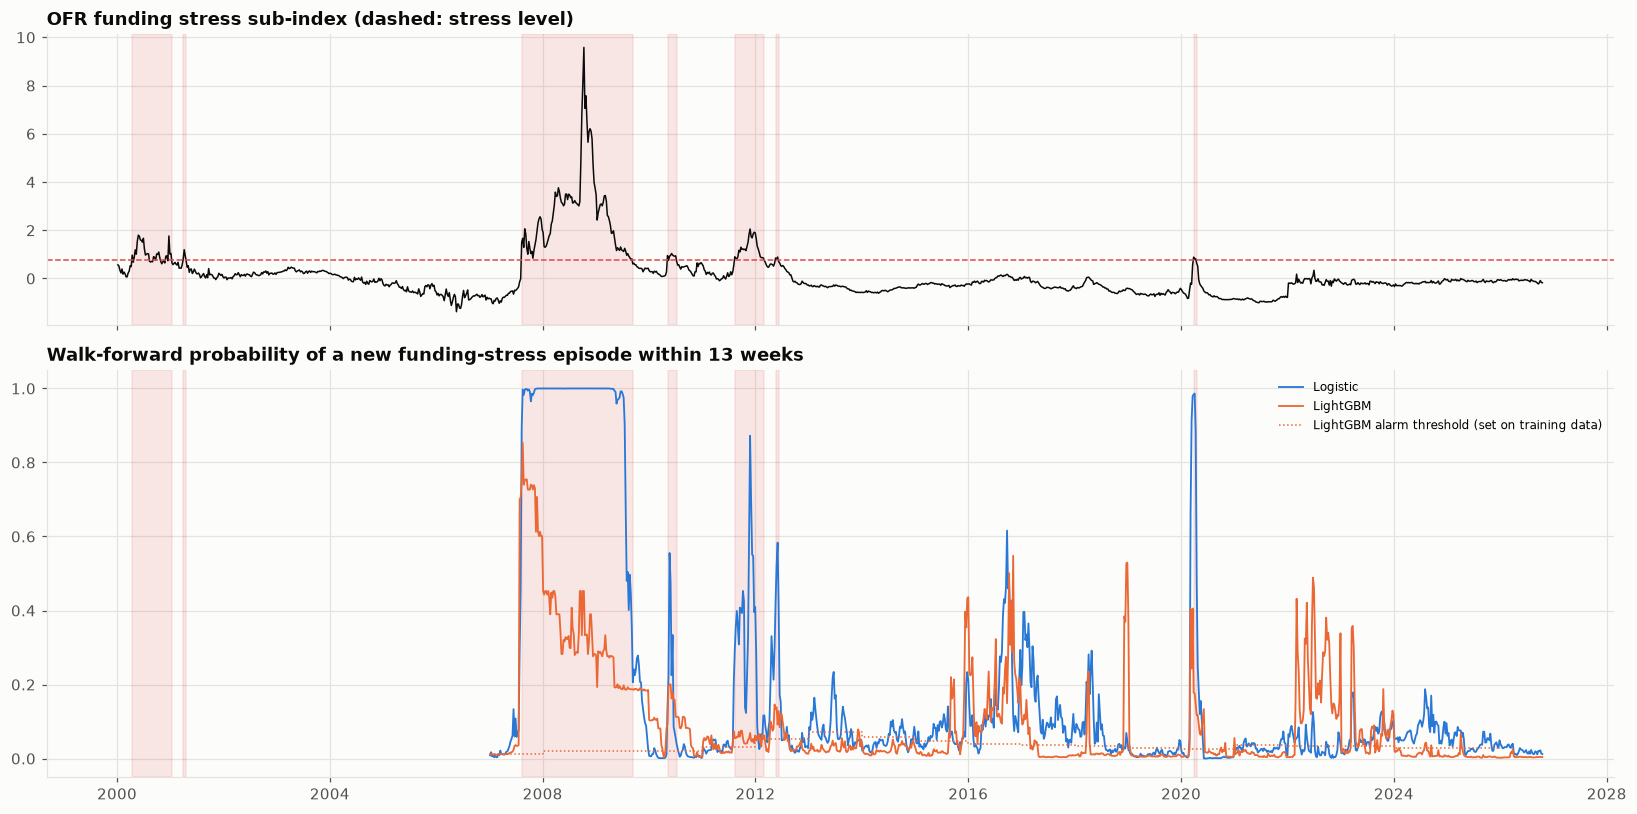

In [7]:
# --- Chart 1: walk-forward probabilities with episodes
fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 7.5),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.4]},
)
ax = axes[0]
ax.plot(W.index, W["fsi funding"], color=INK, lw=1)
ax.axhline(STRESS_LEVEL, color=STATUS["red"], ls="--", lw=1)
ax.set_title("OFR funding stress sub-index (dashed: stress level)")
ax = axes[1]
for name in ["Logistic", "LightGBM"]:
    ax.plot(P.index, P[name], color=MODEL_COLORS[name], lw=1.2, label=name)
ax.step(
    TH.index.map(lambda y: pd.Timestamp(f"{y}-01-01")),
    TH["LightGBM"],
    where="post",
    color=MODEL_COLORS["LightGBM"],
    ls=":",
    lw=1,
    label="LightGBM alarm threshold (set on training data)",
)
ax.set_title(
    "Walk-forward probability of a new funding-stress episode within"
    f" {HORIZON} weeks"
)
ax.legend(fontsize=8)
for a_ in axes:
    for _, e in episodes.iterrows():
        a_.axvspan(
            e["start"],
            e["end"] + pd.Timedelta(weeks=1),
            color=STATUS["red"],
            alpha=0.12,
        )
plt.tight_layout()
save_fig(fig, "01_probability_history")
plt.show()

## 6. Today's reading

The final models are refitted on all usable weeks. Each indicator gets a traffic light from its percentile against its own history since 2000, oriented so that red always means *more stress*: green below the 75th percentile, amber 75th–90th, red above the 90th. Indicators where lower values mean stress (reserves growth, the term slope) are flipped. TreeSHAP shows which indicators push today's LightGBM probability up or down.

In [8]:
med_all = usable[FEATURES].median()
final = {
    name: m.fit(usable[FEATURES].fillna(med_all), usable["y"])
    for name, m in make_models().items()
}
today = data[FEATURES].iloc[[-1]].fillna(med_all)
p_now = {
    name: float(m.predict_proba(today)[:, 1][0]) for name, m in final.items()
}
th_now = {
    name: np.quantile(
        m.predict_proba(usable[FEATURES].fillna(med_all))[:, 1][
            usable["y"].to_numpy() == 0
        ],
        1 - TARGET_FALSE_ALARM,
    )
    for name, m in final.items()
}
contrib = pd.Series(
    final["LightGBM"].predict(today, pred_contrib=True)[0][:-1], index=FEATURES
)

FLIP = {"reserves Δ13w %", "10y–2y slope"}
lights = []
for f in FEATURES:
    hist = data[f].dropna()
    v = today[f].iloc[0]
    pct = (hist <= v).mean() * 100
    pct_stress = 100 - pct if f in FLIP else pct
    lights.append({
        "indicator": f,
        "value": v,
        "percentile (stress-oriented)": pct_stress,
        "light": (
            "red"
            if pct_stress >= 90
            else "amber" if pct_stress >= 75 else "green"
        ),
        "SHAP (log-odds)": contrib[f],
    })
lights = (
    pd.DataFrame(lights)
    .set_index("indicator")
    .sort_values("SHAP (log-odds)", ascending=False)
)
print(
    f"As of {data.index[-1]:%d %b %Y}: P(new funding-stress episode within"
    f" {HORIZON} weeks) = "
    + " · ".join(
        f"{n} {p:.1%} (alarm at {th_now[n]:.1%})" for n, p in p_now.items()
    )
)
print(
    "Lights: "
    + ", ".join(f"{k} {v}" for k, v in lights["light"].value_counts().items())
)
lights.round(2)

As of 16 Oct 2026: P(new funding-stress episode within 13 weeks) = Logistic 1.0% (alarm at 6.5%) · LightGBM 0.3% (alarm at 2.4%)
Lights: green 18, amber 4, red 2


,value,percentile (stress-oriented),light,SHAP (log-odds)
indicator,,,,
10y–2y slope,0.35,70.11,green,0.13
Baa spread (bp),146.00,1.87,green,0.12
Δ4w VIX,5.18,89.73,amber,0.08
Δ4w OFR credit,0.19,83.84,amber,0.06
OFR equity valuation,-0.50,14.15,green,0.06
Δ4w OFR volatility,0.58,88.58,amber,0.05
VIX,19.99,63.36,green,0.04
Δ13w Baa spread,-13.00,35.50,green,0.02
CP – T-bill (bp),5.00,7.61,green,0.00


## 7. Results dashboard

In [9]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.1,
    column_widths=[0.62, 0.38],
    specs=[[{"colspan": 2}, None], [{}, {"type": "table"}]],
    subplot_titles=(
        (
            "Probability of a new funding-stress episode within"
            f" {HORIZON} weeks (walk-forward), episodes shaded"
        ),
        "Today's drivers (LightGBM SHAP, log-odds)",
        "Indicator traffic lights",
    ),
)
for name in ["Logistic", "LightGBM"]:
    dash.add_trace(
        go.Scatter(
            x=P.index,
            y=P[name],
            name=name,
            line=dict(color=MODEL_COLORS[name], width=1.4),
        ),
        1,
        1,
    )
for _, e in episodes.iterrows():
    dash.add_vrect(
        x0=e["start"],
        x1=e["end"] + pd.Timedelta(weeks=1),
        fillcolor=STATUS["red"],
        opacity=0.12,
        line_width=0,
        row=1,
        col=1,
    )
top = lights["SHAP (log-odds)"].abs().sort_values().tail(10).index
dash.add_trace(
    go.Bar(
        y=list(top),
        x=lights.loc[top, "SHAP (log-odds)"],
        orientation="h",
        showlegend=False,
        marker_color=[
            STATUS["red"] if v > 0 else STATUS["green"]
            for v in lights.loc[top, "SHAP (log-odds)"]
        ],
    ),
    2,
    1,
)
tbl = lights.sort_values("percentile (stress-oriented)", ascending=False).head(
    14
)
dash.add_trace(
    go.Table(
        header=dict(
            values=["Indicator", "Value", "Pctile", ""],
            fill_color=SURFACE,
            align="left",
        ),
        cells=dict(
            values=[
                tbl.index,
                tbl["value"].round(2),
                tbl["percentile (stress-oriented)"].round(0),
                ["●"] * len(tbl),
            ],
            font=dict(
                color=[
                    [INK_2] * len(tbl),
                    [INK_2] * len(tbl),
                    [INK_2] * len(tbl),
                    [STATUS[l] for l in tbl["light"]],
                ]
            ),
            align="left",
            height=24,
        ),
    ),
    2,
    2,
)
status = "ALARM" if p_now["LightGBM"] > th_now["LightGBM"] else "no alarm"
dash.update_layout(
    height=950,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=1.04, x=0.6),
    margin=dict(t=140),
    title=dict(
        x=0.01,
        text=(
            f"<b>Funding stress early warning · {data.index[-1]:%d %b %Y}:"
            f" {status}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>P(new episode within"
            f" {HORIZON} weeks): LightGBM {p_now['LightGBM']:.1%} (alarm at"
            f" {th_now['LightGBM']:.1%}), logistic {p_now['Logistic']:.1%} ·"
            " walk-forward AUC LightGBM"
            f" {scoreboard.loc['LightGBM', 'AUC']:.2f}, logistic"
            f" {scoreboard.loc['Logistic', 'AUC']:.2f}</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")
scoreboard.to_csv(OUT_DIR / "walk_forward_scoreboard.csv")
P.to_csv(OUT_DIR / "walk_forward_probabilities.csv")
lights.to_csv(OUT_DIR / "indicator_traffic_lights.csv")
episodes.to_csv(OUT_DIR / "funding_stress_episodes.csv", index=False)
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

Weekly data January 2000 – October 2026, walk-forward from 2007 (five test episodes: 2007–09, 2010, 2011–12, May 2012, March 2020):

**The simplest model wins.** The best single indicator, chosen each year by noise-to-signal ratio, has a walk-forward AUC of **0.79** (90% block-bootstrap interval 0.64–0.94). It flags 3 of 5 episodes with a median lead of 13 weeks and about 0.8 false-alarm spells a year. LightGBM reaches only 0.58 and logistic regression 0.47, no better than chance, even though both see all 24 indicators.

With seven episodes in 26 years (84 positive weeks), a multivariate model fits the particular mix of indicators that preceded 2000 and 2007 and does not generalise. That is the standard lesson of early-warning research, reproduced.

**What the winning signal is.** From 2015 the selected indicator is the **fed funds – T-bill spread**: when bank funding costs rise relative to the safest asset, funding stress is building. Before that, the adjusted NFCI and the OFR safe-asset sub-index were chosen. The choice changes with the data, which a committee should know before it relies on any single number.

**The multivariate models catch more episodes but cry wolf.** LightGBM's alarm rule flags all five episodes, but it is on in 31% of calm weeks (1.5 spells a year). Logistic flags four, with a lead of only 4 weeks, and is on in 21% of calm weeks. Thresholds were set for a 20% false-alarm rate on training data, and both drifted above it out of sample.

- **The index did not see March 2023.** The OFR funding sub-index peaked at only 0.34 during the regional-bank run, well below the stress level, because the run was concentrated in uninsured deposits at a handful of banks while system-wide money markets stayed calm. A system-level EWS is not a substitute for monitoring the bank's own deposit concentration.

**Today (16 October 2026): no alarm.** LightGBM gives 0.3% (alarm at 2.4%) and logistic 1.0% (alarm at 6.5%). Two lights are red: the 4-week rise in the CP–T-bill spread (91st percentile) and the level of discount-window borrowing (92nd percentile, still elevated since 2023 because banks now pre-position and test the window).

Four are amber: VIX, credit, volatility and ANFCI momentum. Levels are calm (Baa spread at its 2nd percentile, CP spread at its 8th), so the reading is "momentum to watch", not stress.

**Limitations**

- Seven episodes in 26 years, so every performance number has a wide interval. The bootstrap intervals overlap for LightGBM and logistic.
- The episode definition (threshold 0.75, 8-week merge) is a choice. A lower threshold would add 2000–2001-type episodes and change the rankings.
- The OFR index is revised as its methodology changes, and the historical values used here are the current vintage, not the real-time ones.
- No funding-market microstructure data (repo rates by collateral, FX swap basis), which would sharpen the signal for dollar funding of non-U.S. counterparties.

## References

### Finance and regulation

- Kaminsky, G., Lizondo, S., & Reinhart, C. M. (1998). Leading indicators of currency crises. *IMF Staff Papers, 45*(1), 1–48. https://doi.org/10.2307/3867328
- Monin, P. J. (2019). The OFR Financial Stress Index. *Risks, 7*(1), 25. https://doi.org/10.3390/risks7010025
- Brunnermeier, M. K. (2009). Deciphering the liquidity and credit crunch 2007–2008. *Journal of Economic Perspectives, 23*(1), 77–100. https://doi.org/10.1257/jep.23.1.77
- Basel Committee on Banking Supervision. (2013). *Basel III: The liquidity coverage ratio and liquidity risk monitoring tools*. Bank for International Settlements. https://www.bis.org/publ/bcbs238.htm
- Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association, 89*(428), 1303–1313. https://doi.org/10.1080/01621459.1994.10476870

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., … Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Holopainen, M., & Sarlin, P. (2017). Toward robust early-warning models: A horse race, ensembles and model uncertainty. *Quantitative Finance, 17*(12), 1933–1963. https://doi.org/10.1080/14697688.2017.1357972